In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', '{:.3f}'.format)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving NHL-playoffs-2026.xlsx to NHL-playoffs-2026.xlsx
Saving rink.py to rink.py


Первая колонка в файле - это номер строки, поэтому делаю её индексом (index_col=0). Тогда получается 38 столбцов, как в примере.

In [ ]:
# №1
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

print(events.shape)
events[['Date', 'Away Team', 'Home Team', 'Remaining Time', 'Play Type']].head(10)

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Дата и команды во всех строках одной игры одинаковые, поэтому беру первую строку игры. Счёт в конце игры - это максимум накопленного счёта. Исход определяю по последнему периоду: 3 - основное время, 4 - один овертайм, 5 - два овертайма и т.д.

In [ ]:
# №2
games = events.groupby('Game ID')[['Date', 'Away Team', 'Home Team']].first()

games['Away Score'] = events.groupby('Game ID')['Cumulated Away Score'].max()
games['Home Score'] = events.groupby('Game ID')['Cumulated Home Score'].max()

last_period = events.groupby('Game ID')['Period'].max()

outcome = []
for period in last_period:
    if period == 3:
        outcome.append('Final')
    elif period == 4:
        outcome.append('Final/OT')
    else:
        outcome.append('Final/' + str(period - 3) + 'OT')

games['Outcome'] = outcome

print(games.columns)
games.tail(5)

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')


,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


Формат как в примере: сначала хозяева, потом гости, счёт в том же порядке.

In [ ]:
# №3
def gameInfo(gameId):
    home = games.loc[gameId, 'Home Team']
    away = games.loc[gameId, 'Away Team']
    home_score = str(games.loc[gameId, 'Home Score'])
    away_score = str(games.loc[gameId, 'Away Score'])
    outcome = games.loc[gameId, 'Outcome']
    date = games.loc[gameId, 'Date']
    return home + ' - ' + away + ' (' + home_score + ' - ' + away_score + ', ' + outcome + ', ' + date + ')'

print(gameInfo(games.index[0]))
print(gameInfo(games.index[-1]))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


In [ ]:
# №4
games['Total Score'] = games['Away Score'] + games['Home Score']

games['Total Score'].describe()

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


Число голов целое, поэтому рисую столбик на каждое значение (countplot).

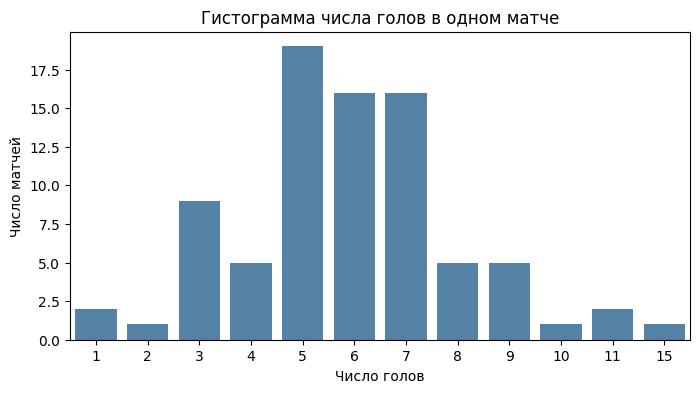

In [ ]:
# №5
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'], color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.title('Гистограмма числа голов в одном матче')
plt.show()

Чаще всего за матч забивали 5 голов (19 матчей), 6 и 7 голов - по 16 матчей. Примерно в 68% игр было от 4 до 7 голов. Среднее (5.9) почти равно медиане (6). Распределение немного скошено вправо: есть несколько очень результативных матчей (10, 11 и 15 голов), а матчей с 1-2 голами всего три. Это понятно, потому что меньше нуля голов быть не может, а сверху ограничения нет.

Ищу все игры с минимальным и максимальным числом голов, потому что таких игр может быть несколько.

In [ ]:
# №6
min_score = games['Total Score'].min()
max_score = games['Total Score'].max()

least = []
for gameId in games.index:
    if games.loc[gameId, 'Total Score'] == min_score:
        least.append(gameInfo(gameId))

most = []
for gameId in games.index:
    if games.loc[gameId, 'Total Score'] == max_score:
        most.append(gameInfo(gameId))

print('Самые нерезультативные игры:')
print(least)
print('Самые результативные игры:')
print(most)

Самые нерезультативные игры:
['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
Самые результативные игры:
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Игроки на льду записаны в 6 столбцах у каждой команды, вратари - в отдельных столбцах. Для каждой игры собираю все имена из этих столбцов в множество set, чтобы каждый игрок посчитался один раз. Пустые ячейки (NaN) пропускаю.

In [ ]:
# №7
player_columns = []
for i in range(1, 7):
    player_columns.append("Away Team's Player on the Ice #" + str(i))
for i in range(1, 7):
    player_columns.append("Home Team's Player on the Ice #" + str(i))
player_columns.append("Away Team's Goalie")
player_columns.append("Home Team's Goalie")

player_count = []
for gameId in games.index:
    game_events = events[events['Game ID'] == gameId]
    players = set()
    for col in player_columns:
        for name in game_events[col]:
            if not pd.isna(name):
                players.add(name)
    player_count.append(len(players))

games['Player Count'] = player_count

game_info = []
for gameId in games.index:
    game_info.append(gameInfo(gameId))
games['Game Info'] = game_info

max_players = games['Player Count'].max()
games[games['Player Count'] == max_players][['Game Info', 'Player Count']]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Больше всего игроков (40) было в матче Montréal Canadiens - Buffalo Sabres (3 - 8). Обычно в игре участвует 38 человек: у каждой команды 18 полевых и 1 вратарь. Значит в этой игре у обеих команд выходили оба вратаря (при счёте 3 - 8 вратаря, скорее всего, меняли). В примере в задании 41 - столько получается, если пустые ячейки (NaN) считать как ещё одного игрока, я их не считаю.

Броски - это shot-on-goal, goal и missed-shot. Сначала определяю, в какие ворота бьёт команда: если хозяева защищают левые ворота (left), то хозяева бьют в правые (X = 89), а гости в левые (X = -89), если правые (right) - наоборот. Потом считаю расстояние до ближайшей точки створа, створ идёт от y = -3 до y = 3.

In [ ]:
# №8
def shot_length(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']

    if row['Team Making the Play'] == row['Home Team']:
        if row["Home Team's Defending Side"] == 'left':
            X = 89
        else:
            X = -89
    else:
        if row["Home Team's Defending Side"] == 'left':
            X = -89
        else:
            X = 89

    if y < -3:
        d = ((x - X)**2 + (y + 3)**2) ** 0.5
    elif y > 3:
        d = ((x - X)**2 + (y - 3)**2) ** 0.5
    else:
        d = abs(x - X)
    return d

is_shot = (events['Play Type'] == 'shot-on-goal') | (events['Play Type'] == 'goal') | (events['Play Type'] == 'missed-shot')

events['Shot Length'] = np.nan
for i in events[is_shot].index:
    events.loc[i, 'Shot Length'] = shot_length(events.loc[i])

print(is_shot.sum())
events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

7266


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Точные броски - shot-on-goal и goal, неточные - missed-shot. Точных бросков почти в два раза больше, поэтому каждую гистограмму нормирую отдельно (stat='density', common_norm=False), чтобы сравнивать доли, а не количества.

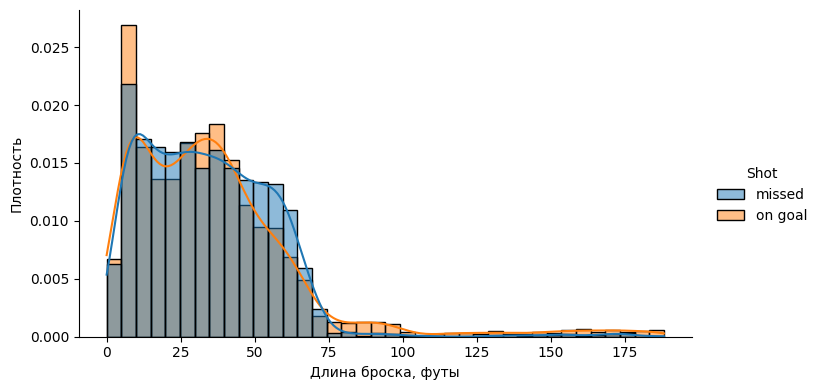

,count,mean,median,max
Shot,,,,
missed,2643,34.014,32.249,185.068
on goal,4623,36.207,31.828,188.215


In [ ]:
# №9
shots = events[is_shot].copy()

shots['Shot'] = 'on goal'
shots.loc[shots['Play Type'] == 'missed-shot', 'Shot'] = 'missed'

sns.displot(data=shots, x='Shot Length', hue='Shot',
            stat='density', common_norm=False, binwidth=5, kde=True,
            height=4, aspect=1.8)
plt.xlabel('Длина броска, футы')
plt.ylabel('Плотность')
plt.show()

shots.groupby('Shot')['Shot Length'].agg(['count', 'mean', 'median', 'max'])

На близких и средних дистанциях (примерно до 70 футов) распределения похожи, медианы почти одинаковые (около 32 футов). Совсем близко к воротам (5-10 футов) и с 30-40 футов точных бросков чуть больше, а с 45-70 футов чаще промахиваются. Главное отличие - у точных бросков длинный хвост: дальше 75 футов неточных почти нет, а точные есть вплоть до 188 футов, то есть почти с другого конца площадки.

Мне кажется, причин несколько. Бросок со своей половины (дальше 89 футов от ворот) - это чаще всего не попытка забить, а выброс шайбы из зоны, который летит в сторону ворот, вратарь его ловит, и это записывается как shot-on-goal. Ещё когда соперник снимает вратаря, можно бросать в пустые ворота издалека. А промахи с такого расстояния, наверное, вообще не записывают как броски, это просто выброс или проброс.

Незаблокированные броски - это те же shot-on-goal, goal и missed-shot, что в №8. Столбец On Goal равен True для точных бросков. При сложении True считается как 1, поэтому sum даёт число точных бросков, а count - число всех бросков.

In [ ]:
# №10
shots['On Goal'] = shots['Shot'] == 'on goal'

on_goal_count = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].sum()
all_count = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].count()

numshots = on_goal_count / all_count
print(numshots)
print()
print(numshots.describe())

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: On Goal, Length: 164, dtype: float64

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: On Goal, dtype: float64


В среднем у команды за игру в створ попадает примерно 64% незаблокированных бросков (медиана тоже 0.639). Разброс большой, от 35% до 86%, но у половины значений доля между 58% и 69%. То есть обычно команда попадает в створ примерно двумя бросками из трёх, а сильные отклонения, скорее всего, случайность отдельных игр, потому что бросков за игру всего несколько десятков.

Для каждой команды беру среднюю долю точных бросков по всем её играм.

In [ ]:
# №11
avgnumshots = numshots.groupby('Team Making the Play').mean()

print('Самая высокая доля:')
print(avgnumshots.sort_values(ascending=False).head(5))
print()
print('Самая низкая доля:')
print(avgnumshots.sort_values().head(5))

Самая высокая доля:
Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: On Goal, dtype: float64

Самая низкая доля:
Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: On Goal, dtype: float64


Самые точные команды - Edmonton Oilers (70.6%), Philadelphia Flyers, Dallas Stars, Minnesota Wild и Colorado Avalanche. Хуже всех Pittsburgh Penguins (55.4%), они заметно отстают от остальных. В целом разница между командами небольшая (от 55% до 71%), а многие команды сыграли всего 4-7 матчей, так что это может быть случайность. Carolina Hurricanes тоже среди наименее точных, но дошла до финала. Наверное, она берёт количеством: в №12 у неё одно из самых больших средних чисел бросков в створ.

Бросок в створ - это shot-on-goal и goal (гол тоже бросок, который попал в ворота). Число игр команды = сколько раз она была хозяином + сколько раз гостем. Общее число бросков и голов команды делю на число её игр.

In [ ]:
# №12
games_played = games['Home Team'].value_counts() + games['Away Team'].value_counts()

on_goal = shots[shots['On Goal'] == True]
goals = events[events['Play Type'] == 'goal']

avgshots = pd.DataFrame()
avgshots['Shot'] = on_goal['Team Making the Play'].value_counts() / games_played
avgshots['Goal'] = goals['Team Making the Play'].value_counts() / games_played
avgshots = avgshots.sort_index()

avgshots

,Shot,Goal
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727
Montréal Canadiens,23.263,2.842


Строю точки по командам с линией регрессии и считаю коэффициент корреляции, чтобы оценить связь числом.

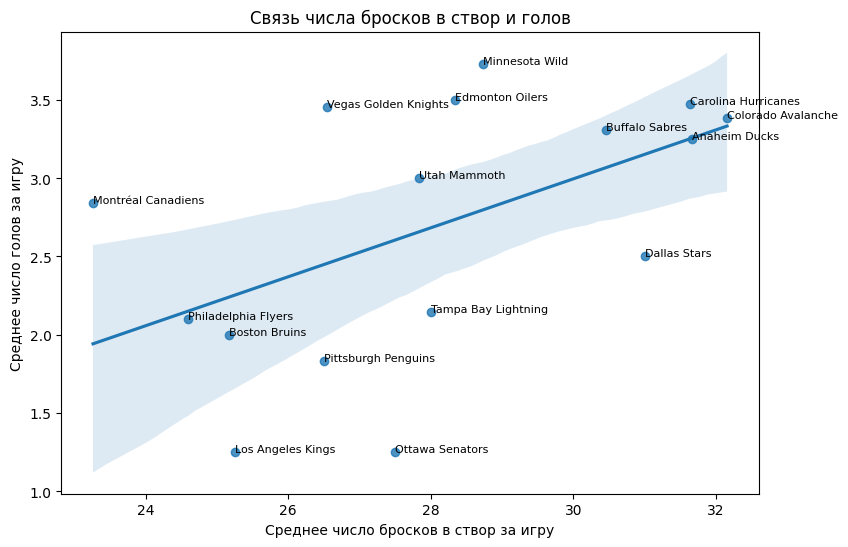

Корреляция: 0.521


In [ ]:
# №13
plt.figure(figsize=(9, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal')
for team in avgshots.index:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']), fontsize=8)
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.title('Связь числа бросков в створ и голов')
plt.show()

print('Корреляция:', round(avgshots['Shot'].corr(avgshots['Goal']), 3))

Связь положительная: команды, которые больше бросают в створ, в среднем больше забивают (корреляция 0.52). Но связь не очень сильная, доверительная область широкая и есть исключения. Например, Montréal Canadiens бросали меньше всех, но забивали почти 3 гола за игру, а Dallas Stars бросали много, а забивали всего 2.5. Ottawa Senators и Los Angeles Kings забивали очень мало при среднем числе бросков. Ещё точек всего 16, и некоторые команды сыграли мало игр, поэтому сильный вывод делать нельзя. На голы влияет не только количество бросков, но и то, откуда бросают, и как играет вратарь соперника.

Здесь считаю все удары, вместе с заблокированными (blocked-shot). value_counts сортирует по убыванию, поэтому нужная игра первая.

In [ ]:
# №14
play_type = events['Play Type']
all_shots = events[(play_type == 'shot-on-goal') | (play_type == 'goal') | (play_type == 'missed-shot') | (play_type == 'blocked-shot')]

shots_per_game = all_shots['Game ID'].value_counts()
best_game = shots_per_game.index[0]

print('Ударов в матче:', shots_per_game.max())
print(gameInfo(best_game))

Ударов в матче: 208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Нужно, чтобы гости всегда били в левые ворота, а хозяева в правые. Хозяева бьют в правые ворота, когда защищают левые (left), поэтому в периодах, где хозяева защищают правые ворота (right), заменяю (x, y) на (-x, -y). В этом матче это периоды 1, 3, 5, как и сказано в задании (видно в выводе). У blocked-shot в Team Making the Play записана команда, которая била, поэтому для всех ударов это команда бьющего.

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: object


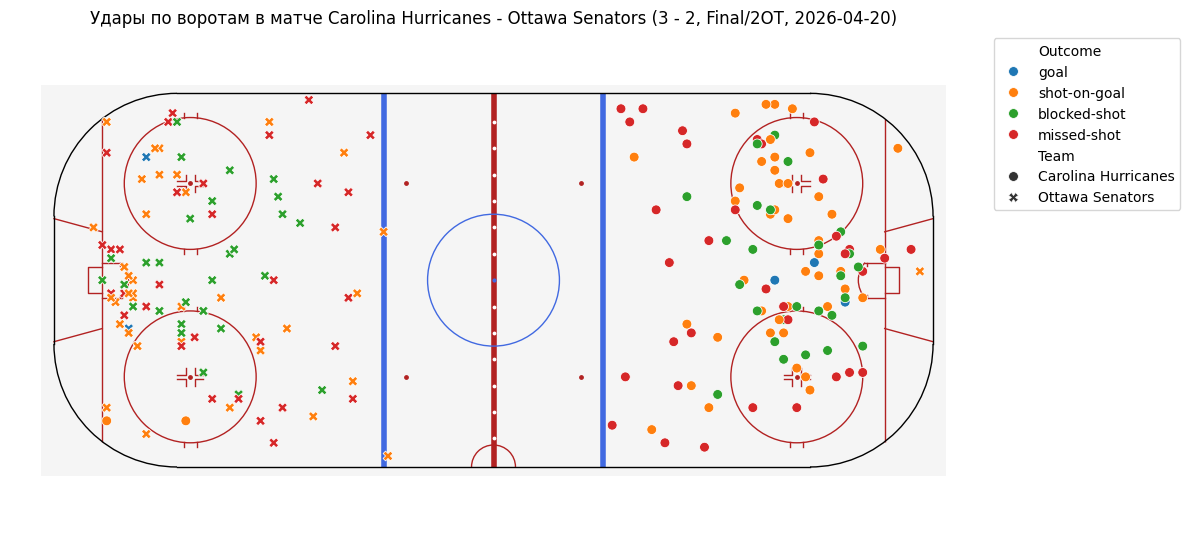

In [ ]:
# №15
from rink import plot_rink

game_shots = all_shots[all_shots['Game ID'] == best_game].copy()

game_shots['x'] = game_shots['X Coordinate on the Ice Rink']
game_shots['y'] = game_shots['Y Coordinate on the Ice Rink']

for i in game_shots.index:
    if game_shots.loc[i, "Home Team's Defending Side"] == 'right':
        game_shots.loc[i, 'x'] = -game_shots.loc[i, 'x']
        game_shots.loc[i, 'y'] = -game_shots.loc[i, 'y']

print(game_shots.groupby('Period')["Home Team's Defending Side"].first())

game_shots['Outcome'] = game_shots['Play Type']
game_shots['Team'] = game_shots['Team Making the Play']

plt.figure(figsize=(12, 5.5))
plot_rink()
sns.scatterplot(data=game_shots, x='x', y='y', hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                s=50)
plt.axis('equal')
plt.axis('off')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.title('Удары по воротам в матче ' + gameInfo(best_game))
plt.tight_layout()
plt.show()

Больше всего ударов из зоны перед воротами и около кругов вбрасывания, издалека (от синей линии) бьют реже. Carolina Hurricanes (справа) ударили немного больше, чем Ottawa Senators (слева): 109 против 99. Голы забивали в основном с близкого расстояния. Заблокированные удары есть по всей зоне атаки.

У гола забивший игрок записан в Player in the Event #1.

In [ ]:
# №16
goals = events[events['Play Type'] == 'goal']

top_goals = goals['Player in the Event #1'].value_counts()
top_goals.head(10)

,count
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Nathan MacKinnon,7
Taylor Hall,7
Mark Stone,7


Передачи записаны в двух столбцах (#2 и #3), поэтому собираю их в один список и считаю.

In [ ]:
# №17
assists_list = []
for name in goals['Player in the Event #2']:
    if not pd.isna(name):
        assists_list.append(name)
for name in goals['Player in the Event #3']:
    if not pd.isna(name):
        assists_list.append(name)

top_assists = pd.Series(assists_list).value_counts()
top_assists.head(10)

,count
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Taylor Hall,12
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Quinn Hughes,11
Kirill Kaprizov,11


У игрока, у которого есть только голы или только передачи, во втором столбце получается NaN, поэтому заменяю его на 0 и складываю. При равных очках выше тот, у кого больше голов.

In [ ]:
# №18
points = pd.DataFrame({'Goals': top_goals, 'Assists': top_assists})
points = points.fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']

points = points.sort_values(by=['Points', 'Goals'], ascending=False)
points.head(10)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


Число игр игрока в данных не записано, поэтому считаю его сама: для каждой игры собираю всех, кто хоть раз был на льду (как в №7), и прибавляю каждому 1. Бросок в створ - shot-on-goal и goal, бросающий записан в Player in the Event #1.

In [ ]:
# №19
player_games = {}
for gameId in games.index:
    game_events = events[events['Game ID'] == gameId]
    players = set()
    for col in player_columns:
        for name in game_events[col]:
            if not pd.isna(name):
                players.add(name)
    for name in players:
        if name in player_games:
            player_games[name] = player_games[name] + 1
        else:
            player_games[name] = 1

player_games = pd.Series(player_games)

shots_by_player = on_goal['Player in the Event #1'].value_counts()

shots_per_game_player = pd.DataFrame()
shots_per_game_player['Shots'] = shots_by_player
shots_per_game_player['Games'] = player_games
shots_per_game_player['Shots per Game'] = shots_per_game_player['Shots'] / shots_per_game_player['Games']

shots_per_game_player.sort_values(by='Shots per Game', ascending=False).head(10)

,Shots,Games,Shots per Game
Player in the Event #1,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667


Считаю так же, как в №19, только для силовых приёмов (hit).

In [ ]:
# №20
hits = events[events['Play Type'] == 'hit']
hits_by_player = hits['Player in the Event #1'].value_counts()

hits_per_game = pd.DataFrame()
hits_per_game['Hits'] = hits_by_player
hits_per_game['Games'] = player_games
hits_per_game['Hits per Game'] = hits_per_game['Hits'] / hits_per_game['Games']

hits_per_game.sort_values(by='Hits per Game', ascending=False).head(10)

,Hits,Games,Hits per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Alexander Petrovic,6,1,6.000
Alex Turcotte,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Carl Grundstrom,15,3,5.000
Marcus Foligno,55,11,5.000
Ivan Barbashev,110,22,5.000


В №19 больше всех бросает в створ Jason Robertson (5 бросков за игру), в №20 больше всех силовых приёмов у Lawson Crouse (6.3 за игру). Среднее здесь - число бросков (или силовых) делённое на число игр, в которых игрок был на льду. Поэтому у тех, кто сыграл 1-4 игры, среднее получается довольно случайным: например, в десятку по силовым попали Alex Turcotte и Alexander Petrovic, у которых всего по одной игре. Надёжнее выглядят игроки с большим числом игр, например у Ivan Barbashev 5 силовых за игру за 22 матча.

Для каждой игры и каждой команды нахожу всех вратарей, которые были на льду, и для каждого гола соперника смотрю, какой вратарь был в воротах. Вратари, которых нет среди пропустивших, сыграли на ноль. Если пустой столбец вратаря только у одной команды, это гол в пустые ворота, и он ни на какого вратаря не записывается.

In [ ]:
# №21

shutout_goalies = set()

for gameId in games.index:
    game_events = events[events['Game ID'] == gameId]
    home = games.loc[gameId, 'Home Team']
    away = games.loc[gameId, 'Away Team']
    game_goals = game_events[game_events['Play Type'] == 'goal']

    home_goalies = set()
    for name in game_events["Home Team's Goalie"]:
        if not pd.isna(name):
            home_goalies.add(name)
    conceded = set()
    for i in game_goals[game_goals['Team Making the Play'] == away].index:
        conceded.add(game_events.loc[i, "Home Team's Goalie"])
    for goalie in home_goalies:
        if goalie not in conceded:
            shutout_goalies.add(goalie)

    away_goalies = set()
    for name in game_events["Away Team's Goalie"]:
        if not pd.isna(name):
            away_goalies.add(name)
    conceded = set()
    for i in game_goals[game_goals['Team Making the Play'] == home].index:
        conceded.add(game_events.loc[i, "Away Team's Goalie"])
    for goalie in away_goalies:
        if goalie not in conceded:
            shutout_goalies.add(goalie)

print('Всего вратарей:', len(shutout_goalies))
sorted(shutout_goalies)

Всего вратарей: 8


['Andrei Vasilevskiy',
 'Arturs Silovs',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Jakub Dobes',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Проверяю, есть ли в данных голы, где не указан ни один вратарь.

In [ ]:
no_goalies = 0
for i in goals.index:
    if pd.isna(goals.loc[i, "Home Team's Goalie"]) and pd.isna(goals.loc[i, "Away Team's Goalie"]):
        no_goalies = no_goalies + 1
print('Голов, где не указан ни один вратарь:', no_goalies)

Голов, где не указан ни один вратарь: 22


Пустых ворот сразу у двух команд быть не может, значит это пропуск в данных. В таком случае беру последнего вратаря этой команды до гола и считаю заново.

In [ ]:
def conceding_goalie(game_events, i, goalie_col, other_col):
    goalie = game_events.loc[i, goalie_col]
    other = game_events.loc[i, other_col]
    if pd.isna(goalie) and pd.isna(other):
        for j in game_events.index:
            if j < i and not pd.isna(game_events.loc[j, goalie_col]):
                goalie = game_events.loc[j, goalie_col]
    return goalie

shutout_goalies2 = set()

for gameId in games.index:
    game_events = events[events['Game ID'] == gameId]
    home = games.loc[gameId, 'Home Team']
    away = games.loc[gameId, 'Away Team']
    game_goals = game_events[game_events['Play Type'] == 'goal']

    home_goalies = set()
    for name in game_events["Home Team's Goalie"]:
        if not pd.isna(name):
            home_goalies.add(name)
    conceded = set()
    for i in game_goals[game_goals['Team Making the Play'] == away].index:
        conceded.add(conceding_goalie(game_events, i, "Home Team's Goalie", "Away Team's Goalie"))
    for goalie in home_goalies:
        if goalie not in conceded:
            shutout_goalies2.add(goalie)
            print(goalie, '-', gameInfo(gameId))

    away_goalies = set()
    for name in game_events["Away Team's Goalie"]:
        if not pd.isna(name):
            away_goalies.add(name)
    conceded = set()
    for i in game_goals[game_goals['Team Making the Play'] == home].index:
        conceded.add(conceding_goalie(game_events, i, "Away Team's Goalie", "Home Team's Goalie"))
    for goalie in away_goalies:
        if goalie not in conceded:
            shutout_goalies2.add(goalie)
            print(goalie, '-', gameInfo(gameId))

print()
print('Всего вратарей:', len(shutout_goalies2))
print(sorted(shutout_goalies2))
print('Убрались из списка:', sorted(shutout_goalies - shutout_goalies2))

Joonas Korpisalo - Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)
Andrei Vasilevskiy - Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Frederik Andersen - Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)
Dan Vladar - Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
Dan Vladar - Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Frederik Andersen - Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)
Scott Wedgewood - Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)
Frederik Andersen - Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)
Brandon Bussi - Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)

Всего вратарей: 6
['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']
Убрались из списка: ['Arturs Silovs', 'Jakub Dobes']


Если считать прямо по столбцам с вратарями, получается 8 вратарей. Но в 22 голах не указан ни один вратарь, это пропуск в данных. Из-за этого в список попадают Arturs Silovs и Jakub Dobes: каждый из них пропустил единственный гол своего матча в овертайме (Philadelphia Flyers - Pittsburgh Penguins 1 - 0 и Montréal Canadiens - Tampa Bay Lightning 0 - 1), но у этого гола вратарь не записан. Если в таких случаях брать последнего вратаря команды до гола, остаётся 6 вратарей, и это правильный ответ.

Frederik Andersen (Carolina Hurricanes) сыграл на ноль три матча, Dan Vladar (Philadelphia Flyers) два. Joonas Korpisalo и Scott Wedgewood попали в список, хотя их команды в этих играх пропускали: они выходили на замену (или их заменили) и за своё время в воротах голов не пропустили. Такие случаи в задании как раз просили учитывать.

Вопрос: какая команда пропускала меньше всего голов за игру?

Для каждого гола пропустившая команда - это соперник забившей. Считаю, сколько голов пропустила каждая команда, и делю на число её игр из №12.

In [ ]:
# №22
conceded_list = []
for i in goals.index:
    if goals.loc[i, 'Team Making the Play'] == goals.loc[i, 'Home Team']:
        conceded_list.append(goals.loc[i, 'Away Team'])
    else:
        conceded_list.append(goals.loc[i, 'Home Team'])

goals_against = pd.Series(conceded_list).value_counts() / games_played
goals_against = goals_against.sort_values()

print('Меньше всего голов за игру пропускала команда:')
print(goals_against.index[0])
print('Голов за игру:')
print(round(goals_against.iloc[0], 2))
print()
print(goals_against)

Меньше всего голов за игру пропускала команда:
Carolina Hurricanes
Голов за игру:
2.05

Carolina Hurricanes    2.053
Tampa Bay Lightning    2.286
Philadelphia Flyers    2.400
Pittsburgh Penguins    2.667
Ottawa Senators        2.750
Vegas Golden Knights   2.818
Colorado Avalanche     2.846
Montréal Canadiens     2.947
Buffalo Sabres         3.000
Los Angeles Kings      3.250
Boston Bruins          3.333
Anaheim Ducks          3.500
Minnesota Wild         3.545
Dallas Stars           3.833
Utah Mammoth           3.833
Edmonton Oilers        4.333
Name: count, dtype: float64


Меньше всего голов за игру пропускала Carolina Hurricanes (2.05), и она дошла до финала. Больше всего пропускали Edmonton Oilers (4.33 за игру).